# Steg 3: Hva ser modellen?

Hvert EKG er nå 1024 tall, altså én prikk i et rom med 1024 retninger. Vi spør: ligger EKG med samme diagnose nær hverandre, og **hvilke diagnoser blander modellen**?

## 1. Valgene våre

In [72]:
K = 10                # antall nærmeste naboer vi teller for hvert EKG
PCA_KOMPONENTER = 50  # PCA ned til 50 tall før UMAP (raskere, mindre støy)
UMAP_NABOER = 15      # hvor mange naboer UMAP prøver å holde sammen
SEED = 305            # samme tilfeldighet hver gang

## 2. Last inn embeddingene og fasiten

In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

emb = np.load("data/embeddings.npy")      # 1291 EKG × 1024 tall
utvalg = pd.read_csv("utvalg.csv")        # rad nr. i her er samme EKG som rad nr. i i emb
print(emb.shape)

klasser = utvalg["klasse"].to_numpy(dtype=str)   # fasiten: én diagnose per rad, som vanlig numpy-tekst
klassenavn = sorted(set(klasser))
print(len(klassenavn), "klasser")

(1100, 1024)
11 klasser


## 3. En tegnefunksjon: én farge og form per diagnose (13 klasser er flere enn standardfargene)

In [74]:
farger = plt.cm.tab20.colors
former = ["o", "s", "^", "D"]


def plott(xy, tittel):
    plt.figure(figsize=(10, 8))
    for i, k in enumerate(klassenavn):
        denne_klassen = klasser == k
        plt.scatter(xy[denne_klassen, 0], xy[denne_klassen, 1], s=16,
                    color=farger[i], marker=former[i % 4], label=k)
    plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.title(tittel)
    plt.show()

## 4. PCA: finn retningene med mest spredning

De to første retningene viser 16% av spredningen


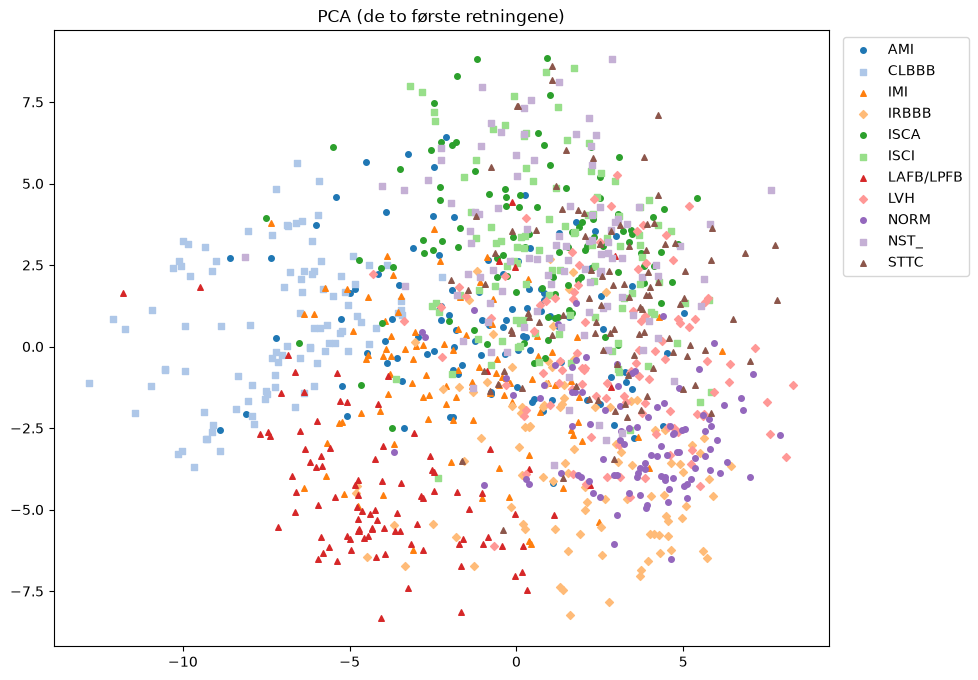

In [75]:
from sklearn.decomposition import PCA

pca = PCA(n_components=PCA_KOMPONENTER, random_state=SEED)
emb_pca = pca.fit_transform(emb)

andel = pca.explained_variance_ratio_[:2].sum()
print(f"De to første retningene viser {andel:.0%} av spredningen")

plott(emb_pca, "PCA (de to første retningene)")

## 5. UMAP: tegn et kart der naboer forblir naboer

c:\Anaconda\envs\MOD300\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Anaconda\envs\MOD300\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


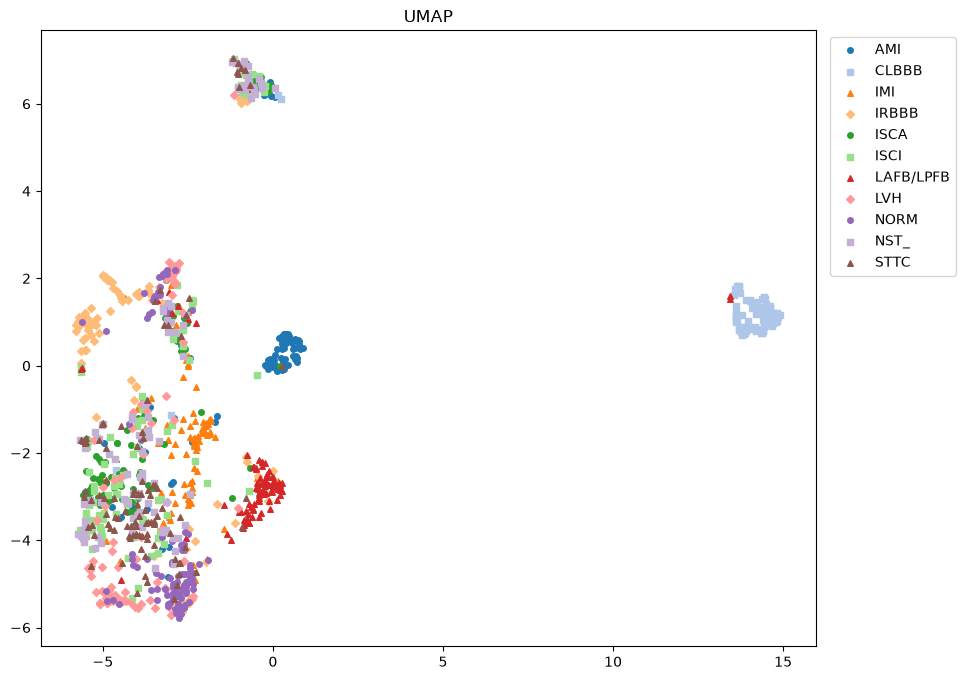

In [76]:
import umap

kart = umap.UMAP(n_neighbors=UMAP_NABOER, min_dist=0.1, random_state=SEED)
emb_umap = kart.fit_transform(emb_pca)

plott(emb_umap, "UMAP")

## 6. Finn de nærmeste naboene til hvert EKG

In [77]:
from sklearn.neighbors import NearestNeighbors


def finn_naboer(X, avstand, k=K):
    sok = NearestNeighbors(n_neighbors=k + 1, metric=avstand, algorithm="brute")
    sok.fit(X)
    avstander, naboer = sok.kneighbors(X)
    return naboer[:, 1:]          # første kolonne er EKG-et selv, så den hopper vi over


# Tre rom å sammenligne: det fulle rommet og de to flate kartene.
# Cosinus måler vinkelen mellom vektorene, som er vanlig for embeddings.
naboer_1024 = finn_naboer(emb, "cosine")
naboer_pca = finn_naboer(emb_pca[:, :2], "euclidean")
naboer_umap = finn_naboer(emb_umap, "euclidean")

print(naboer_1024.shape)    # 1291 EKG × 10 naboer

(1100, 10)


## 7. Tallene: k-NN-enighet og silhouette, sammenlignet med tilfeldig

In [78]:
from sklearn.metrics import silhouette_score


def knn_enighet(naboer, etiketter):
    like = 0
    for i in range(len(etiketter)):
        for j in naboer[i]:
            if etiketter[j] == etiketter[i]:
                like += 1
    return like / naboer.size     # andel av alle nabo-par som har samme diagnose


# Nullnivå: hva får vi hvis diagnosene deles ut helt tilfeldig?
stokket = np.random.default_rng(SEED).permutation(klasser)


def vis_tall(navn, X, avstand, naboer):
    knn = knn_enighet(naboer, klasser)
    tilfeldig = knn_enighet(naboer, stokket)
    sil = silhouette_score(X, klasser, metric=avstand)
    print(f"{navn:7}  k-NN {knn:.2f}  (tilfeldig {tilfeldig:.2f})   silhouette {sil:.2f}")


vis_tall("1024-D", emb, "cosine", naboer_1024)
vis_tall("PCA-2", emb_pca[:, :2], "euclidean", naboer_pca)
vis_tall("UMAP-2", emb_umap, "euclidean", naboer_umap)

1024-D   k-NN 0.54  (tilfeldig 0.09)   silhouette 0.06
PCA-2    k-NN 0.29  (tilfeldig 0.09)   silhouette -0.05
UMAP-2   k-NN 0.50  (tilfeldig 0.09)   silhouette 0.06


## 8. Hvilke diagnoser er naboer? Rad = EKG-ets diagnose, kolonne = naboens diagnose

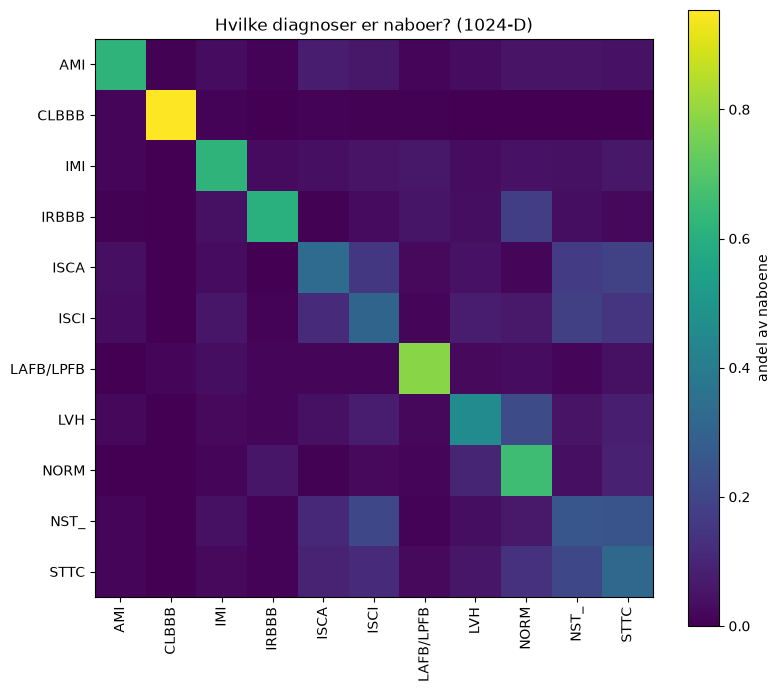

k-NN-enighet per klasse (diagonalen):
NST_         0.26
ISCI         0.31
STTC         0.32
ISCA         0.33
LVH          0.46
IRBBB        0.60
AMI          0.62
IMI          0.62
NORM         0.66
LAFB/LPFB    0.78
CLBBB        0.95
dtype: float64


In [79]:
def naboblanding(naboer):
    # Tell: for hvert EKG, hvilke diagnoser har naboene?
    tabell = pd.DataFrame(0.0, index=klassenavn, columns=klassenavn)
    for i in range(len(klasser)):
        for j in naboer[i]:
            tabell.loc[klasser[i], klasser[j]] += 1

    # Gjør tellingen om til andeler: del hver rad på summen av raden
    for klasse in klassenavn:
        tabell.loc[klasse] = tabell.loc[klasse] / tabell.loc[klasse].sum()
    return tabell


M = naboblanding(naboer_1024)

plt.figure(figsize=(9, 8))
plt.imshow(M, cmap="viridis")
plt.colorbar(label="andel av naboene")
plt.xticks(range(len(klassenavn)), klassenavn, rotation=90)
plt.yticks(range(len(klassenavn)), klassenavn)
plt.title("Hvilke diagnoser er naboer? (1024-D)")
plt.show()

print("k-NN-enighet per klasse (diagonalen):")
print(pd.Series(np.diag(M), index=klassenavn).sort_values().round(2))

## 9. De mest blandede parene

In [80]:
def mest_blandet(M, antall):
    par = []
    for a in klassenavn:
        for b in klassenavn:
            if a != b:
                par.append((M.loc[a, b], a, b))
    par.sort(reverse=True)
    return par[:antall]


for andel, a, b in mest_blandet(M, 8):
    print(f"{a:10} har {andel:.0%} naboer som er {b}")

NST_       har 25% naboer som er STTC
LVH        har 22% naboer som er NORM
STTC       har 21% naboer som er NST_
NST_       har 21% naboer som er ISCI
ISCA       har 18% naboer som er STTC
ISCI       har 18% naboer som er NST_
IRBBB      har 18% naboer som er NORM
ISCA       har 17% naboer som er NST_


## 10. Er funnet det samme i alle tre rommene?

In [81]:
def parliste(M):
    """Ett tall per par: snittet av A->B og B->A, så paret ikke telles to ganger."""
    par = {}
    for i in range(len(klassenavn)):
        for j in range(i + 1, len(klassenavn)):
            a = klassenavn[i]
            b = klassenavn[j]
            par[a + "–" + b] = (M.loc[a, b] + M.loc[b, a]) / 2
    return pd.Series(par)


P = pd.DataFrame()
P["1024-D"] = parliste(naboblanding(naboer_1024))
P["PCA-2"] = parliste(naboblanding(naboer_pca))
P["UMAP-2"] = parliste(naboblanding(naboer_umap))

print("Spearman: er rangeringen av parene lik? (1 = helt lik)")
print(P.corr(method="spearman").round(2))
print()
print("De 5 mest blandede parene i hvert rom:")
for navn in P.columns:
    print(f"{navn:7}", list(P[navn].nlargest(5).index))

Spearman: er rangeringen av parene lik? (1 = helt lik)
        1024-D  PCA-2  UMAP-2
1024-D    1.00   0.75    0.94
PCA-2     0.75   1.00    0.78
UMAP-2    0.94   0.78    1.00

De 5 mest blandede parene i hvert rom:
1024-D  ['NST_–STTC', 'ISCI–NST_', 'LVH–NORM', 'ISCA–NST_', 'ISCA–STTC']
PCA-2   ['IRBBB–NORM', 'LVH–NORM', 'ISCI–NST_', 'ISCA–ISCI', 'ISCA–NST_']
UMAP-2  ['ISCI–NST_', 'NST_–STTC', 'ISCA–NST_', 'LVH–NORM', 'ISCA–ISCI']


## 11. Tåler funnet andre valg?

Valgene i blokk 1 bestemmes **før** vi ser resultatene. Vi justerer dem ikke for å få et «bedre» svar. Her endrer vi dem i stedet for å se om **konklusjonen holder**.

In [82]:
print("Antall naboer K:")
for k in [5, 10, 20]:
    nb = finn_naboer(emb, "cosine", k)
    topp = [f"{a}–{b}" for _, a, b in mest_blandet(naboblanding(nb), 3)]
    print(f"  K={k:2}  k-NN {knn_enighet(nb, klasser):.2f}   topp 3: {topp}")

print("UMAP-naboer:")
for n in [5, 15, 50]:
    xy = umap.UMAP(n_neighbors=n, min_dist=0.1, random_state=SEED).fit_transform(emb_pca)
    nb = finn_naboer(xy, "euclidean")
    topp = [f"{a}–{b}" for _, a, b in mest_blandet(naboblanding(nb), 3)]
    print(f"  n={n:2}  k-NN {knn_enighet(nb, klasser):.2f}   topp 3: {topp}")

Antall naboer K:
  K= 5  k-NN 0.56   topp 3: ['NST_–STTC', 'STTC–NST_', 'LVH–NORM']
  K=10  k-NN 0.54   topp 3: ['NST_–STTC', 'LVH–NORM', 'STTC–NST_']
  K=20  k-NN 0.51   topp 3: ['NST_–STTC', 'LVH–NORM', 'STTC–NST_']
UMAP-naboer:


c:\Anaconda\envs\MOD300\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Anaconda\envs\MOD300\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  n= 5  k-NN 0.50   topp 3: ['NST_–ISCI', 'STTC–NST_', 'NST_–STTC']


c:\Anaconda\envs\MOD300\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Anaconda\envs\MOD300\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  n=15  k-NN 0.50   topp 3: ['NST_–ISCI', 'ISCI–NST_', 'STTC–NST_']


c:\Anaconda\envs\MOD300\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Anaconda\envs\MOD300\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  n=50  k-NN 0.50   topp 3: ['NST_–STTC', 'ISCI–NST_', 'NST_–ISCI']


## 12. Se på EKG-ene selv: hvorfor ligner de?

Tallene sier *at* diagnoser blandes. Her tegner vi to EKG som modellen mener er naboer oppå hverandre, så vi kan se *hvorfor*. Ett par er et eksempel, ikke et bevis.

In [83]:
AVLEDNINGER = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]

def les_ekg(ecg_id):
    return np.load("data/signaler/" + str(ecg_id) + ".npy")   # rå signal, 5000 × 12, i millivolt

def klasse_til(ecg_id):
    rad = utvalg[utvalg["ecg_id"] == ecg_id]
    return rad["klasse"].values[0]

def finn_nabopar(klasse_a, klasse_b):
    """Første EKG med klasse_a som har et EKG med klasse_b blant sine nærmeste naboer."""
    for i in range(len(klasser)):
        if klasser[i] == klasse_a:
            for j in naboer_1024[i]:
                if klasser[j] == klasse_b:
                    return utvalg["ecg_id"][i], utvalg["ecg_id"][j]


def ett_slag(kurve):
    """Klipper ut ett hjerteslag: 0,5 sekund før og etter det største utslaget."""
    topp = np.argmax(np.abs(kurve[250:4750])) + 250    # ikke helt i kanten av opptaket
    return kurve[topp - 250 : topp + 250]               # 250 målinger = 0,5 sekund


def tegn_over_hverandre(ecg_a, ecg_b, avledning, tittel, normalisert=False):
    nr = AVLEDNINGER.index(avledning)
    tid_slag = (np.arange(500) - 250) / 500             # fra -0,5 til 0,5 sekunder rundt toppen
    plt.figure(figsize=(8, 4))
    for ecg_id in [ecg_a, ecg_b]:
        signal = les_ekg(ecg_id)
        if normalisert:
            signal = (signal - signal.mean()) / (signal.std() + 1e-8)   # samme som i steg 2
        plt.plot(tid_slag, ett_slag(signal[:, nr]), label="EKG " + str(ecg_id) + " (" + klasse_til(ecg_id) + ")")
    plt.xlabel("sekunder fra toppen av slaget")
    plt.ylabel("normalisert" if normalisert else "millivolt")
    plt.title(tittel + " · avledning " + avledning)
    plt.legend()
    plt.show()
    print("a:", a, type(a))

### Par 1: IRBBB og CRBBB, to grader av høyre grenblokk. V1 er der det synes best

In [ ]:
a, b = finn_nabopar("IRBBB", "CLBBB")
tegn_over_hverandre(a, b, "V1", "IRBBB og CLRBB som modellen mener er naboer")

TypeError: cannot unpack non-iterable NoneType object

### Par 2: LVH og NORM, før og etter normalisering. LVH stilles ofte ut fra høye utslag i V5

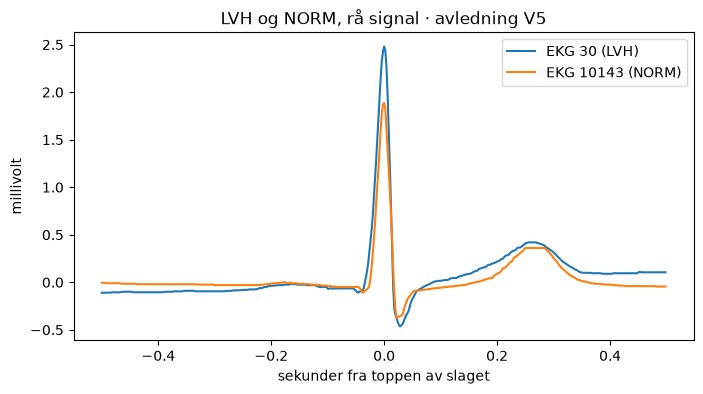

a: 30 <class 'numpy.int64'>


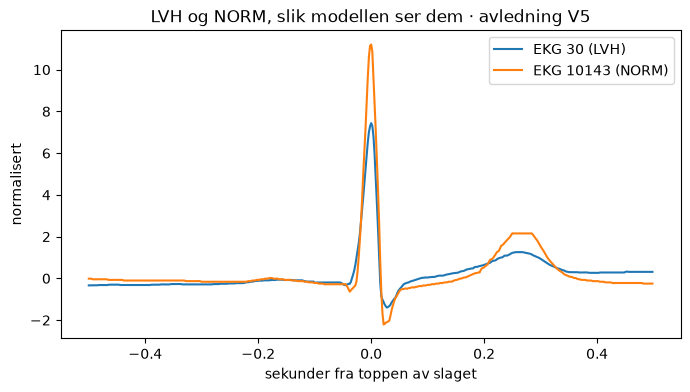

a: 30 <class 'numpy.int64'>


In [85]:
a, b = finn_nabopar("LVH", "NORM")
tegn_over_hverandre(a, b, "V5", "LVH og NORM, rå signal")
tegn_over_hverandre(a, b, "V5", "LVH og NORM, slik modellen ser dem", normalisert=True)

### Et EKG som ikke passer inn: EKG 8408

Merket LAFB (venstre fremre fascikkelblokk), men 9 av 10 naboer er CLBBB (komplett venstre grenblokk). Kardiologens fritekst sier «Linksschenkelblock» (venstre grenblokk), og rapporten er ikke bekreftet av et menneske. Kan modellen ha rett og etiketten feil?

In [ ]:
rad_8408 = utvalg.index[utvalg["ecg_id"] == 8408][0]
nabo = utvalg["ecg_id"][naboer_1024[rad_8408][0]]        # den aller nærmeste naboen
print("Naboene til EKG 8408:", list(klasser[naboer_1024[rad_8408]]))

tegn_over_hverandre(8408, nabo, "V1", "EKG 8408 (merket LAFB) og nærmeste nabo")